In [61]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import convolve

In [62]:
# 定义文件路径
PREDICT_PATH = "F:/B208/High_density/ML_generation/density_map/img41.txt"
REAL_DIR = "F:/B208/High_density/ML_generation/txt_train/img41.txt"
image_size = 512  # 图像尺寸
WIDTH = 4
LENGTH = 4

In [63]:
# 读取数据
def read_data(file_path):
    data = np.loadtxt(file_path)
    return data[:, :4], data[:, 4]  # 坐标和密度（前四列是坐标，第五列是密度）

# 读取预测和真实数据
predict_coords, predict_density = read_data(PREDICT_PATH)
real_coords, real_density = read_data(REAL_DIR)

# 初始化密度图
predict_density_map = np.zeros((image_size, image_size))
real_density_map = np.zeros((image_size, image_size))

# 填充密度图
for (x_start, x_end, y_start, y_end), density in zip(predict_coords, predict_density):
    predict_density_map[int(y_start):int(y_end), int(x_start):int(x_end)] = density  # 确保索引为整数

for (x_start, x_end, y_start, y_end), density in zip(real_coords, real_density):
    real_density_map[int(y_start):int(y_end), int(x_start):int(x_end)] = density  # 确保索引为整数

# 定义 3x3 平均卷积核
kernel = np.ones((1, 1)) / 1  # 归一化，确保不会改变总体密度

# 对密度图进行平滑处理
predict_density_map = convolve(predict_density_map, kernel, mode='reflect')
real_density_map = convolve(real_density_map, kernel, mode='reflect')

# 计算密度差异图
density_diff_image = predict_density_map - real_density_map


# 填充预测密度图（不累加，每个块内取平均值）
for pred_coord, pred_value in zip(predict_coords, predict_density):
    x_start, x_end, y_start, y_end = map(int, pred_coord)

    # 确保索引在合法范围内
    x_start, x_end = max(0, x_start), min(image_size, x_end)
    y_start, y_end = max(0, y_start), min(image_size, y_end)

    # 计算区域面积（防止除 0）
    area = (x_end - x_start) * (y_end - y_start)
    avg_value = pred_value if area == 0 else pred_value / area  # 计算均匀分布的密度值

    # 直接赋值，不累加
    predict_density_map[y_start:y_end, x_start:x_end]

# 填充真实密度图（不累加，每个块内取平均值）
for real_coord, real_value in zip(real_coords, real_density):
    x_start, x_end, y_start, y_end = map(int, real_coord)

    # 确保索引在合法范围内
    x_start, x_end = max(0, x_start), min(image_size, x_end)
    y_start, y_end = max(0, y_start), min(image_size, y_end)

    # 计算区域面积（防止除 0）
    area = (x_end - x_start) * (y_end - y_start)
    avg_value = real_value if area == 0 else real_value / area  # 计算均匀分布的密度值

    # 直接赋值，不累加
    real_density_map[y_start:y_end, x_start:x_end]

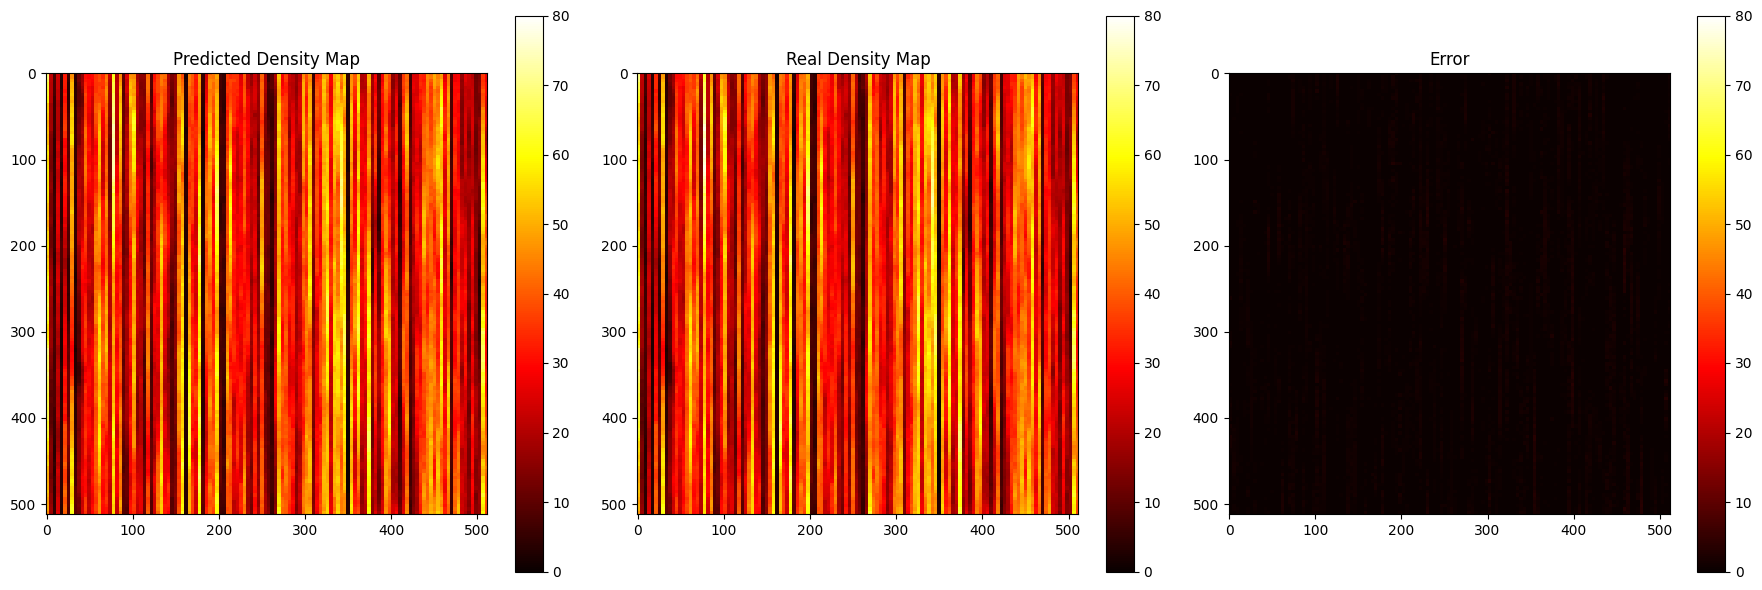

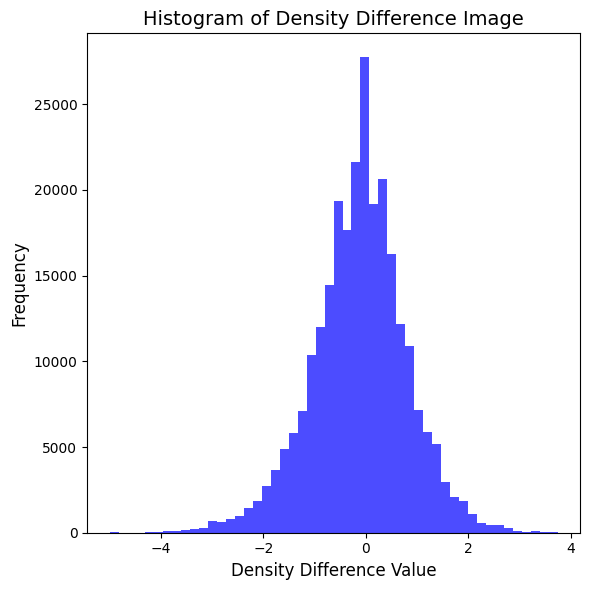

In [67]:
# 绘制三张子图
fig, axs = plt.subplots(1, 3, figsize=(18, 6))

# 预测密度图
im1 = axs[0].imshow(predict_density_map, cmap="hot", interpolation="nearest")
axs[0].set_title("Predicted Density Map")
fig.colorbar(im1, ax=axs[0])

# 真实密度图
im2 = axs[1].imshow(real_density_map, cmap="hot", interpolation="nearest")
axs[1].set_title("Real Density Map")
fig.colorbar(im2, ax=axs[1])

# 密度差异图
im3 = axs[2].imshow(density_diff_image, cmap="hot", interpolation="nearest")
axs[2].set_title("Error")
fig.colorbar(im3, ax=axs[2])
# 设置颜色范围
for im in [im1, im2, im3]:
    im.set_clim(0, 80)
plt.tight_layout()
plt.show()
plt.figure(figsize=(6, 6))
# 计算并绘制柱状图
plt.hist(density_diff_image.flatten(), bins=50, color='blue', alpha=0.7)

# 设置图表标题和标签
plt.title('Histogram of Density Difference Image', fontsize=14)
plt.xlabel('Density Difference Value', fontsize=12)
plt.ylabel('Frequency', fontsize=12)

# 显示图表
plt.tight_layout()
plt.show()